# Can cell images predict liver-cell toxicity? Three models on the same compound-aware splits

**Group project · bioimaging · my implementation**, Seid Adem

> **Why this matters, in plain language.** Before a chemical (a drug candidate, a pesticide) reaches people, its
> toxicity has to be assessed. **Cell Painting** is a cheap, fast screen: human liver cells are exposed to a compound,
> six fluorescent dyes light up different parts of the cell (nucleus, endoplasmic reticulum, mitochondria, Golgi and
> actin, RNA), and image analysis turns the pictures into thousands of numbers describing cell shape and texture: a
> **morphology profile**. If profiles predict toxicity measured in other assays, imaging could prioritise which
> chemicals need expensive follow-up. ([Lessons 1–3](../LESSONS.md))

The course builds an XGBoost model on one random split and a neural network separately. I ask:

1. **Which endpoint, and why?** (class balance, biological match)
2. **How strong is a one-number baseline:** "how much did the compound change the cells at all"?
3. **Logistic regression vs XGBoost vs a PyTorch MLP** on **identical, compound-aware** splits, with paired comparisons.
4. **Which cell compartments carry the signal?** (single-channel and leave-one-channel-out models)

*Data: compound-level Cell Painting profiles of primary human hepatocytes (1,086 compounds × 4,434 features, provided by
the course) and ToxCast cytotoxicity labels (US EPA), as distributed with the course.*

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

from dsls.textclf import MLPClassifier, predict_proba, train_with_early_stopping

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
DATA = Path("../../../data/raw/bioimaging")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
SEED = 0
torch.set_num_threads(4)

profiles = pd.read_parquet(DATA / "level6_axiom_selected_features.parquet")
oasis = pd.read_csv(DATA / "v5_oasis_03Sept2024_simple.csv").drop_duplicates("PREFERRED_NAME")
cytotox = pd.read_parquet(DATA / "toxcast_cytotox_binary.parquet")
FEATURES = [c for c in profiles.columns if c.startswith("Feature_")]
CHANNELS = sorted({c.split("_")[1] for c in FEATURES})
print(f"{len(profiles):,} compounds × {len(FEATURES):,} features; channels: "
      + ", ".join(f"{ch} ({sum(c.split('_')[1] == ch for c in FEATURES)})" for ch in CHANNELS))  # fmt: skip

1,086 compounds × 4,434 features; channels: AGP (767), Brightfield (766), DNA (642), ER (746), Mito (759), RNA (754)


## 1 · Linking images to labels, and choosing an endpoint

Compound names in the profiles are matched to the course's identifier table (`OASIS_ID`), then to the ToxCast
cytotoxicity table, as in the course notebooks. ToxCast summarises cytotoxicity per cell type and per tissue; every
column is a possible endpoint.

In [2]:
linked = profiles.merge(oasis[["PREFERRED_NAME", "OASIS_ID", "INCHIKEY"]], how="left", left_on="Metadata_compound",
                        right_on="PREFERRED_NAME", validate="many_to_one")  # fmt: skip
print(f"compounds matched to an OASIS_ID: {linked['OASIS_ID'].notna().sum():,} of {len(linked):,}")
data = linked.merge(cytotox, on="OASIS_ID", how="inner")
endpoints = [c for c in cytotox.columns if c != "OASIS_ID"]
balance = pd.DataFrame(
    {"compounds tested": data[endpoints].notna().sum(), "active share": data[endpoints].mean()}
)
display(
    balance[balance["compounds tested"] >= 300]
    .sort_values("compounds tested", ascending=False)
    .round(2)
    .head(8)
)

compounds matched to an OASIS_ID: 791 of 1,086


,compounds tested,active share
cell_type__HepG2,548,0.24
tissue__liver,548,0.24
tissue__breast,548,0.19
cell_type__HCT116,547,0.11
cell_type__MDA-kb2,547,0.16
cell_type__VM7,547,0.15
tissue__cervix,547,0.12
cell_type__HEK293T,547,0.18


In [3]:
ENDPOINT = "tissue__liver"  # HepG2 liver-cell cytotoxicity
df = data.dropna(subset=[ENDPOINT]).reset_index(drop=True)
y = df[ENDPOINT].astype(int).to_numpy()
X = df[FEATURES]

# Compound-aware groups: the first block of the InChIKey encodes the molecule's connectivity, so salts and
# stereoisomers of the same molecule share it and must stay on the same side of a split.
skeleton = df["INCHIKEY"].str[:14].fillna(df["Metadata_compound"])
groups = pd.factorize(skeleton)[0]
shared = pd.Series(groups).value_counts()
print(f"endpoint {ENDPOINT}: {len(df)} compounds, {y.sum()} active ({y.mean():.0%}); "
      f"{(shared > 1).sum()} molecules appear as more than one compound entry ({shared[shared > 1].sum()} rows)")  # fmt: skip
print(f"missing feature values: {X.isna().to_numpy().mean():.2%}; typical feature scale: median |value| = "
      f"{np.nanmedian(np.abs(X.to_numpy())):.2f}")  # fmt: skip

endpoint tissue__liver: 548 compounds, 130 active (24%); 0 molecules appear as more than one compound entry (0 rows)
missing feature values: 0.00%; typical feature scale: median |value| = 0.29


**Endpoint: `tissue__liver`** (cytotoxicity in liver cells): **548 compounds, 130 active (24 %).** Three reasons:

* it is one of the two best-covered endpoints after linking (548 compounds), with a workable balance;
* the Cell Painting experiment used **liver cells** (primary human hepatocytes), so the biology matches;
* cytotoxicity is what a morphology screen should detect most directly.

**Two data checks worth recording.** Only **791 of 1,086** profiled compounds match the identifier table by name, so a
quarter of the imaging data can't be used with these labels (matching on chemical identifiers rather than names
would recover some). And the compound-aware check found **no molecule present twice**, so grouped and plain
stratified splits are identical here. It costs one line to check, and the scores below need no correction for it.

## 2 · The evaluation protocol, and a one-number baseline

All models below are evaluated on **the same 25 train/test splits**: 5-fold cross-validation grouped by molecule and
stratified by activity, repeated 5 times. Two metrics:

* **ROC-AUC:** how well the model ranks an active compound above an inactive one (0.5 = chance);
* **PR-AUC** (average precision): how clean the top of the ranking is; with 22 % actives, a random ranking scores
  about 0.22. It answers the practical question "if I test the compounds the model flags first, how many are toxic?"

> **The baseline.** The profiles are normalised to untreated (DMSO) control cells, so a compound that leaves the
> cells looking normal has values near zero. A one-number summary of "how much did the compound change the cells"
> (the average absolute value across all 4,434 features) needs no training at all. If toxic compounds simply disturb
> cells more, this number alone will rank them well.

In [4]:
REPEATS = 5
SPLITS = [
    list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r).split(X, y, groups))
    for r in range(REPEATS)
]


def evaluate(scores_by_repeat):
    return pd.DataFrame(
        [{"ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s)} for s in scores_by_repeat]
    )


strength = np.nanmean(np.abs(X.to_numpy()), axis=1)
results = {"baseline: profile strength (no training)": evaluate([strength])}
print(
    f"profile strength, actives vs inactives (median): {np.median(strength[y == 1]):.2f} vs {np.median(strength[y == 0]):.2f}"
)
print(f"chance level: ROC-AUC 0.5, PR-AUC {y.mean():.2f}")
display(results["baseline: profile strength (no training)"].round(3))

profile strength, actives vs inactives (median): 0.41 vs 0.31
chance level: ROC-AUC 0.5, PR-AUC 0.24


,ROC-AUC,PR-AUC
0,0.78,0.541


**The one-number baseline is already strong: ROC-AUC 0.78, PR-AUC 0.54** (chance: 0.50 and 0.24), with no training
at all. Toxic compounds change the cells more (median strength 0.41 vs 0.31). That is the bar every model has to
clear: a model that only learns "this compound disturbed the cells" adds nothing beyond this number.

## 3 · Logistic regression, XGBoost and a neural network

* **Logistic regression** with its regularisation strength chosen by an inner 3-fold search on each training set;
* **XGBoost** (gradient-boosted trees, the course's choice) with sensible fixed settings and the class weight set
  from each training set;
* **a PyTorch MLP** (my 04.1 network: dropout → 256 hidden units → dropout → output), trained with early stopping on
  a validation slice carved out of each training set.

Each model is fitted 25 times, once per training set, and predicts only compounds it never saw.

In [5]:
class TorchMLP(BaseEstimator, ClassifierMixin):
    # scikit-learn wrapper: impute + standardise, hold out 15 % of the training set for early stopping
    def __init__(self, hidden=256, epochs=60, patience=6, lr=1e-3, seed=SEED):
        self.hidden, self.epochs, self.patience, self.lr, self.seed = hidden, epochs, patience, lr, seed

    def fit(self, X, y):
        self.prep_ = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X)
        Z = np.clip(self.prep_.transform(X), -10, 10).astype(np.float32)
        tr, va = train_test_split(np.arange(len(y)), test_size=0.15, stratify=y, random_state=self.seed)
        g = torch.Generator().manual_seed(self.seed)

        def loader(idx, shuffle):
            ds = TensorDataset(torch.from_numpy(Z[idx]), torch.from_numpy(np.asarray(y)[idx]).long())
            return DataLoader(ds, batch_size=64, shuffle=shuffle, generator=g if shuffle else None)

        self.model_ = MLPClassifier(Z.shape[1], 2, hidden=self.hidden, seed=self.seed)
        self.history_ = train_with_early_stopping(self.model_, loader(tr, True), loader(va, False),
                                                  score_fn=balanced_accuracy_score, max_epochs=self.epochs,
                                                  patience=self.patience, lr=self.lr, device="cpu", seed=self.seed)  # fmt: skip
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        Z = np.clip(self.prep_.transform(X), -10, 10).astype(np.float32)
        dl = DataLoader(
            TensorDataset(torch.from_numpy(Z), torch.zeros(len(Z), dtype=torch.long)), batch_size=256
        )
        return predict_proba(self.model_, dl, "cpu")


def make_lr():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegressionCV(Cs=[1e-4, 1e-3, 1e-2, 1e-1], cv=3, scoring="roc_auc", max_iter=3000))  # fmt: skip


def make_xgb(y_train):
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.5,
                         scale_pos_weight=(y_train == 0).sum() / max(y_train.sum(), 1), eval_metric="logloss",
                         random_state=SEED, n_jobs=4)  # fmt: skip


MODELS = {
    "logistic regression": lambda yt: make_lr(),
    "XGBoost": make_xgb,
    "PyTorch MLP": lambda yt: TorchMLP(),
}


def oof_scores(make, columns=FEATURES, repeats=REPEATS):
    out = []
    for splits in SPLITS[:repeats]:
        s = np.zeros(len(y))
        for train, test in splits:
            model = make(y[train]).fit(X.iloc[train][columns], y[train])
            s[test] = model.predict_proba(X.iloc[test][columns])[:, 1]
        out.append(s)
    return out


oof = {}
for name, make in MODELS.items():
    start = time.perf_counter()
    oof[name] = oof_scores(make)
    results[name] = evaluate(oof[name])
    print(f"{name:20s} {time.perf_counter() - start:5.0f} s")

table = pd.concat({k: v.agg(["mean", "min", "max"]).T for k, v in results.items()}).unstack()
table.columns = [f"{m} ({s})" for m, s in table.columns]
display(table.round(3))

logistic regression     13 s


XGBoost                402 s


PyTorch MLP             13 s


,mean (ROC-AUC),mean (PR-AUC),min (ROC-AUC),min (PR-AUC),max (ROC-AUC),max (PR-AUC)
baseline: profile strength (no training),0.780,0.541,0.780,0.541,0.780,0.541
logistic regression,0.818,0.640,0.810,0.621,0.831,0.656
XGBoost,0.839,0.640,0.829,0.633,0.846,0.646
PyTorch MLP,0.822,0.640,0.796,0.608,0.837,0.658


,comparison,metric,mean difference,repeats where first is better
0,XGBoost − logistic regression,ROC-AUC,0.021,5 of 5
1,XGBoost − logistic regression,PR-AUC,-0.000,2 of 5
2,PyTorch MLP − logistic regression,ROC-AUC,0.004,3 of 5
3,PyTorch MLP − logistic regression,PR-AUC,-0.000,2 of 5
4,XGBoost − PyTorch MLP,ROC-AUC,0.017,4 of 5
5,XGBoost − PyTorch MLP,PR-AUC,0.000,2 of 5
6,XGBoost − baseline: profile strength (no train...,ROC-AUC,0.058,5 of 5
7,XGBoost − baseline: profile strength (no train...,PR-AUC,0.099,5 of 5


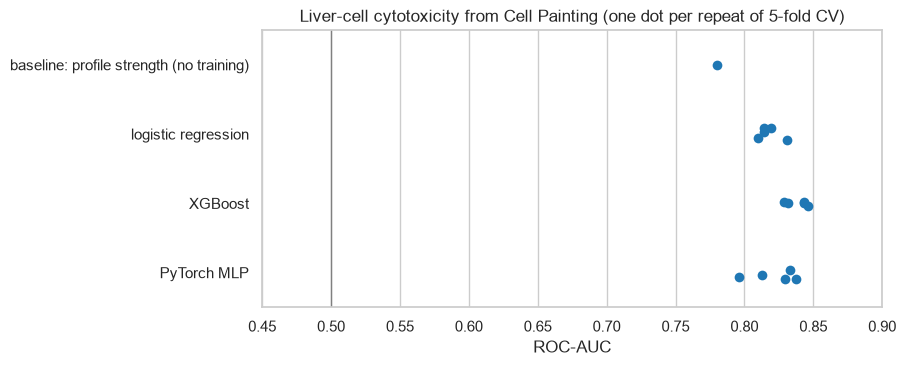

In [6]:
# Paired comparison: differences on the same splits (one value per repeat)
pairs = [("XGBoost", "logistic regression"), ("PyTorch MLP", "logistic regression"), ("XGBoost", "PyTorch MLP"),
         ("XGBoost", "baseline: profile strength (no training)")]  # fmt: skip
rows = []
for a, b in pairs:
    for metric in ("ROC-AUC", "PR-AUC"):
        b_values = results[b][metric].to_numpy()  # the baseline has one value (it involves no random split)
        d = results[a][metric].to_numpy() - (b_values if len(b_values) > 1 else b_values[0])
        rows.append({"comparison": f"{a} − {b}", "metric": metric, "mean difference": d.mean(),
                     "repeats where first is better": f"{(d > 0).sum()} of {len(d)}"})  # fmt: skip
display(pd.DataFrame(rows).round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
long = pd.concat({k: v for k, v in results.items()}).reset_index(level=0).rename(columns={"level_0": "model"})
sns.stripplot(data=long, x="ROC-AUC", y="model", size=7, ax=ax, color="tab:blue")
ax.axvline(0.5, color="grey", lw=1)
ax.set(
    xlim=(0.45, 0.9),
    ylabel="",
    title="Liver-cell cytotoxicity from Cell Painting (one dot per repeat of 5-fold CV)",
)
fig.savefig(FIGURES / "01_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**All three models clear the baseline, and by about the same amount:**

| | ROC-AUC | PR-AUC |
|---|---|---|
| profile strength (no training) | 0.780 | 0.541 |
| logistic regression | 0.818 | 0.640 |
| XGBoost | **0.839** | 0.640 |
| PyTorch MLP | 0.822 | 0.640 |

* Learning from the full profile adds **+0.04 to +0.06 ROC-AUC and +0.10 PR-AUC** over the baseline, so the profile
  carries information beyond "how disturbed the cells are".
* **XGBoost ranks best by ROC-AUC, in all 5 repeats** (+0.021 over logistic regression), but **PR-AUC is identical**
  for all three models (0.640): at the top of the ranking, where a toxicologist would start testing, they are equally
  good. Which model looks best depends on the metric.
* **The neural network is not better than logistic regression** (+0.004, ahead in 3 of 5 repeats) and varies most
  between repeats (0.796–0.837). With 548 compounds and 4,434 features there isn't enough data for its extra
  flexibility to pay off. It also took 14 s against XGBoost's 414 s.

> **In plain language.** Deep learning is not automatically better. On small tabular datasets a regularised linear
> model or gradient-boosted trees is usually as good and much cheaper, and a fair comparison uses the same splits
> and more than one metric.

## 4 · Which cell compartments carry the signal?

Each Cell Painting channel images a different compartment: **DNA** (nucleus), **ER** (endoplasmic reticulum),
**RNA** (nucleoli and cytoplasmic RNA), **AGP** (actin, Golgi and plasma membrane), **Mito** (mitochondria), plus
**Brightfield** (unstained cell outline and texture). With 4,434 anonymous features, per-feature importances would be
hard to read; asking **what one channel achieves alone**, and **what is lost without it**, is more robust. Logistic
regression (fast and as good as the others here) on 3 of the 5 repeats.

took 43 s; all channels together (same 3 repeats): ROC-AUC 0.821


,features,ROC-AUC alone,ROC-AUC without it,PR-AUC alone,loss without it
channel,,,,,
Brightfield,766,0.814,0.818,0.600,0.003
Mito,759,0.807,0.823,0.606,-0.002
AGP,767,0.798,0.814,0.600,0.007
ER,746,0.791,0.825,0.593,-0.004
RNA,754,0.787,0.828,0.589,-0.007
DNA,642,0.761,0.811,0.564,0.010


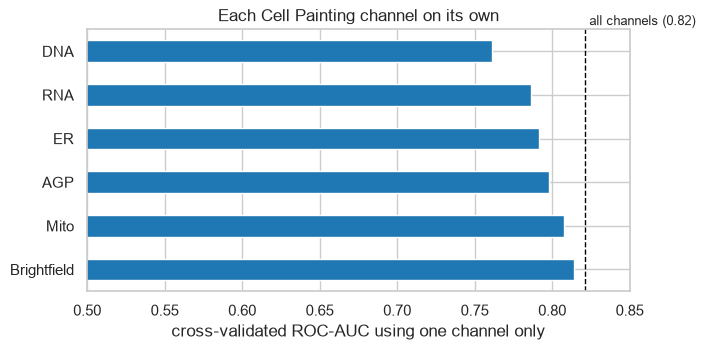

In [7]:
rows = []
start = time.perf_counter()
for ch in CHANNELS:
    cols = [c for c in FEATURES if c.split("_")[1] == ch]
    rest = [c for c in FEATURES if c.split("_")[1] != ch]
    alone = evaluate(oof_scores(lambda yt: make_lr(), cols, repeats=3)).mean()
    without = evaluate(oof_scores(lambda yt: make_lr(), rest, repeats=3)).mean()
    rows.append({"channel": ch, "features": len(cols), "ROC-AUC alone": alone["ROC-AUC"],
                 "ROC-AUC without it": without["ROC-AUC"], "PR-AUC alone": alone["PR-AUC"]})  # fmt: skip
channels = pd.DataFrame(rows).set_index("channel").sort_values("ROC-AUC alone", ascending=False)
all_lr = results["logistic regression"]["ROC-AUC"].iloc[:3].mean()
channels["loss without it"] = all_lr - channels["ROC-AUC without it"]
print(
    f"took {time.perf_counter() - start:.0f} s; all channels together (same 3 repeats): ROC-AUC {all_lr:.3f}"
)
display(channels.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
channels["ROC-AUC alone"].plot.barh(ax=ax, color="tab:blue")
ax.axvline(all_lr, color="black", ls="--", lw=1)
ax.text(all_lr, len(channels) - 0.4, f" all channels ({all_lr:.2f})", fontsize=9)
ax.set(xlim=(0.5, 0.85), xlabel="cross-validated ROC-AUC using one channel only", ylabel="",
       title="Each Cell Painting channel on its own")  # fmt: skip
fig.savefig(FIGURES / "02_channels.png", dpi=150, bbox_inches="tight")
plt.show()

**The signal is spread across the cell, and heavily duplicated.** Every channel on its own reaches ROC-AUC
0.76–0.81, close to all channels together (0.821), and **removing any one channel costs at most 0.01** (three of the
six even score marginally higher without it, which is noise, not improvement).

* **Brightfield alone (0.814)** is as good as anything else. It is the unstained image: no dye, just the cell's
  outline and texture. A dying cell rounds up and detaches, which is visible without staining.
* **DNA alone is weakest (0.761)** but loses the most when removed (0.010).

> **In plain language.** This is what redundancy looks like: the compartments all respond together to a toxic
> insult, so no single stain is essential for *this* question. That does not mean the dyes are useless. It suggests
> that for simple cytotoxicity a cheaper assay might do, and that the specialised channels should be judged on
> harder questions, such as distinguishing *mechanisms* of toxicity.

## 5 · What do the confident mistakes look like?

In [8]:
p = np.mean(oof["XGBoost"], axis=0)
view = df[["Metadata_compound", "Metadata_compound_target", "Metadata_compound_research_area"]].assign(
    active=y, predicted=p.round(2), strength=strength.round(2))  # fmt: skip
pct = pd.Series(strength).rank(pct=True)
missed = view[view["active"] == 1].nsmallest(10, "predicted")
alarms = view[view["active"] == 0].nlargest(10, "predicted")
print(
    f"  10 most confidently missed actives: median strength percentile {pct[missed.index].median():.0%}; "
    f"all actives {pct[y == 1].median():.0%}"
)
print(f"  10 most confident false alarms: median strength percentile {pct[alarms.index].median():.0%}; "
      f"all inactives {pct[y == 0].median():.0%}")  # fmt: skip
print("\nmost confidently missed actives:")
display(missed)
print("most confident false alarms:")
display(alarms)

  10 most confidently missed actives: median strength percentile 25%; all actives 79%
  10 most confident false alarms: median strength percentile 95%; all inactives 42%

most confidently missed actives:


,Metadata_compound,Metadata_compound_target,Metadata_compound_research_area,active,predicted,strength
149,Cyprodinil,Androgen Receptor; Fungal,Infection; Endocrinology,1,0.00,0.27
15,8-Hydroxyquinoline,Antibiotic; Bacterial,Cancer,1,0.01,0.30
109,Celecoxib,COX,Inflammation/Immunology; Cancer,1,0.01,0.28
150,Cyproheptadine,5-HT Receptor; Apoptosis,Neurological Disease; Cardiovascular Disease,1,0.01,0.28
175,Diniconazole,Bacterial,Infection,1,0.01,0.30
221,Fenhexamid,Fungal,Infection,1,0.01,0.34
389,Pentetic acid,Fluorescent Dye,Others,1,0.01,0.38
451,Roxithromycin,Antibiotic; Bacterial,Infection,1,0.01,0.28
537,Vitamin B12,Endogenous Metabolite,Metabolic Disease; Cancer,1,0.01,0.28
89,Buprofezin,Oxidative Phosphorylation; Reactive Oxygen Spe...,Others,1,0.02,0.26


most confident false alarms:


,Metadata_compound,Metadata_compound_target,Metadata_compound_research_area,active,predicted,strength
405,Plicamycin,Antibiotic; Bacterial; DNA/RNA Synthesis; Glut...,Cancer; Infection,0,1.00,6.11
535,Vandetanib,Apoptosis; Autophagy; VEGFR,Cancer,0,0.99,1.01
48,Artesunate,Ferroptosis; Parasite; STAT; Virus Protease,Cancer,0,0.98,0.62
489,Temsirolimus,Apoptosis; Autophagy; Bacterial; mTOR,Cancer,0,0.97,1.18
130,Cladribine,Adenosine Deaminase; Apoptosis,Cardiovascular Disease; Cancer,0,0.91,0.64
539,Volinanserin,5-HT Receptor,Neurological Disease,0,0.91,0.60
133,Climbazole,Fungal,Infection,0,0.86,0.37
95,Calcitriol,Drug Metabolite; Endogenous Metabolite; VD/VDR,Cancer,0,0.84,0.39
426,Pyriproxyfen,Autophagy; Parasite,Infection,0,0.82,0.49
90,Buspirone,5-HT Receptor; Dopamine Receptor; Reactive Oxy...,Cancer; Neurological Disease,0,0.78,0.40


**The mistakes follow the baseline, which is the main weakness.** The ten most confidently missed toxic compounds
have unusually *weak* profiles (median strength percentile 25 %, against 79 % for actives in general): they are toxic
in the ToxCast assay but barely changed these cells. The ten most confident false alarms are the opposite (95 % vs
42 %): compounds that strongly changed cell morphology without counting as cytotoxic in the reference assay. Several
are cancer drugs that act on cell growth and division.

Two reminders rather than findings: the labels come from **different assays, cell types and exposure times** than the
imaging, so some disagreement is expected and the "errors" are not necessarily wrong; and the model still leans
heavily on overall response strength.

## Conclusions

1. **Cell Painting profiles do predict liver-cell cytotoxicity:** ROC-AUC 0.82–0.84, PR-AUC 0.64 against a 24 %
   active rate, on compounds held out of training.
2. **A one-number baseline reaches 0.78,** so most of the apparent accuracy is "did the compound disturb the cells
   at all". Models add a real but modest amount on top (+0.10 PR-AUC).
3. **The three model families tie on PR-AUC** (0.640); XGBoost wins on ROC-AUC in every repeat, the neural network
   does not beat logistic regression. Report more than one metric before choosing.
4. **No single channel is essential:** each alone reaches 0.76–0.81 and removing any costs ≤ 0.01. Brightfield, the
   unstained image, does as well as the dyes for this endpoint.

**Limitations.** 548 compounds after linking (a quarter of the profiles lost to name-based matching), one endpoint,
one cell system; labels come from other assays, so disagreement is partly label noise; the models use fixed
settings rather than a nested search, and single-concentration compound-level profiles discard dose information.

*Data: Cell Painting profiles of primary human hepatocytes and ToxCast binary labels, both as distributed with the
course, in the git-ignored `data/raw/bioimaging/`. Runtime: about 8 minutes on an Apple-silicon laptop (XGBoost is
most of it).*